# Power System Load Type Prediction

**Objective:** Build an end-to-end, CPU-friendly, leakage-free machine learning system that classifies electricity consumption into `Light_Load`, `Medium_Load`, or `Maximum_Load` using historical electricity data.

This notebook follows the phased workflow defined in `AGENTS.md`:
1. **Phase 1 — Setup and Audit**
2. **Phase 2 — Data Cleaning and Validation**
3. **Phase 3 — Chronological Data Splitting**
4. **Phase 4 — Exploratory Data Analysis (Development Data Only)**
5. **Phase 5 — Feature Engineering & Preprocessing**
6. Phases 6–7 — Model Comparison & Tuning
7. Phases 8–10 — Final Evaluation, Explainability & Persistence

## Phase 1 — Setup and Data Audit

In [1]:
from pathlib import Path
import json
import sys

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.load_prediction.data import (
    load_raw_data,
    audit_dataset,
    clean_dataset,
    chronological_split,
    save_audit_report,
)

raw_df = load_raw_data(PROJECT_ROOT / "data" / "load_data.csv")
audit = audit_dataset(raw_df)
print(json.dumps(audit, indent=2))
raw_df.head()

{
  "row_count": 35041,
  "column_count": 9,
  "columns": [
    "Date_Time",
    "Usage_kWh",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "NSM",
    "Load_Type"
  ],
  "date_range": {
    "min": "2018-01-01T00:00:00",
    "max": "2018-12-31T23:45:00"
  },
  "class_counts": {
    "Light_Load": 18073,
    "Medium_Load": 9696,
    "Maximum_Load": 7272
  },
  "missing_counts": {
    "Date_Time": 0,
    "Usage_kWh": 1559,
    "Lagging_Current_Reactive.Power_kVarh": 876,
    "Leading_Current_Reactive_Power_kVarh": 1156,
    "CO2(tCO2)": 455,
    "Lagging_Current_Power_Factor": 350,
    "Leading_Current_Power_Factor": 1471,
    "NSM": 455,
    "Load_Type": 0
  },
  "duplicate_timestamps": 1,
  "exact_duplicate_rows": 0,
  "is_monotonic_increasing": false
}


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,2018-01-01 00:15:00,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,2018-01-01 00:30:00,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,2018-01-01 00:45:00,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,2018-01-01 01:00:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,2018-01-01 01:15:00,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


## Phase 2 — Data Cleaning and Validation

Deterministic cleaning rules applied **before** splitting (no data-dependent statistics are learned here; median imputation is deferred to the training pipeline after the chronological split):
- Sort chronologically by `Date_Time` (fixing the 365 daily `00:00` out-of-order rows).
- Preserve all 35,041 rows (including the single duplicate timestamp `2018-12-31 20:00:00`).
- Flag and replace physically invalid Power Factor values (`< 0` or `> 100`) with `NaN`.
- Compare `NSM` with timestamp-derived seconds since midnight, flag disagreements, and replace inconsistent `NSM` values with `NaN`.
- Preserve extreme but plausible `Usage_kWh`, reactive power, and `CO2(tCO2)` measurements.

In [2]:
cleaned_df, cleaning_report = clean_dataset(raw_df)
audit["cleaning_report"] = cleaning_report
save_audit_report(audit, PROJECT_ROOT / "outputs" / "data_quality.json")
print(json.dumps(cleaning_report, indent=2))
cleaned_df.head()

{
  "input_rows": 35041,
  "output_rows": 35041,
  "sorted_chronologically": true,
  "duplicate_timestamps_flagged": 1,
  "power_factor_invalid_replaced_with_nan": {
    "Lagging_Current_Power_Factor": 3226,
    "Leading_Current_Power_Factor": 2685
  },
  "negative_measurements_replaced_with_nan": {
    "Usage_kWh": 0,
    "Lagging_Current_Reactive.Power_kVarh": 0,
    "Leading_Current_Reactive_Power_kVarh": 0,
    "CO2(tCO2)": 0
  },
  "nsm_audit": {
    "non_null_before_cleaning": 34586,
    "out_of_range_0_86400": 1773,
    "disagreed_with_timestamp": 3414
  },
  "missing_counts_after_cleaning": {
    "Date_Time": 0,
    "Usage_kWh": 1559,
    "Lagging_Current_Reactive.Power_kVarh": 876,
    "Leading_Current_Reactive_Power_kVarh": 1156,
    "CO2(tCO2)": 455,
    "Lagging_Current_Power_Factor": 3576,
    "Leading_Current_Power_Factor": 4156,
    "NSM": 3869,
    "Load_Type": 0
  }
}


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type,Lagging_Current_Power_Factor_was_invalid,Leading_Current_Power_Factor_was_invalid,NSM_was_inconsistent
0,2018-01-01 00:00:00,3.420000,3.46,0.0,0.0,70.30,NaN,0.0,Light_Load,0,1,0
1,2018-01-01 00:15:00,8.753692,2.95,0.0,0.0,73.21,100.0,900.0,Light_Load,0,0,0
2,2018-01-01 00:30:00,4.000000,4.46,0.0,0.0,66.77,100.0,1800.0,Light_Load,0,0,0
3,2018-01-01 00:45:00,3.240000,3.28,0.0,0.0,70.28,100.0,NaN,Light_Load,0,0,1
4,2018-01-01 01:00:00,3.310000,3.56,0.0,0.0,68.09,100.0,3600.0,Light_Load,0,0,0


## Phase 3 — Chronological Data Splitting

- **Training:** January – October 2018 (`29,184` rows)
- **Validation:** November 2018 (`2,880` rows)
- **Test (Held-Out):** December 2018 (`2,977` rows)

All splits are strictly chronological with zero timestamp overlap, and equal timestamps remain in the same partition.

In [3]:
train_df, val_df, test_df, split_summary = chronological_split(cleaned_df)
print(json.dumps(split_summary, indent=2))
assert train_df["Date_Time"].max() < val_df["Date_Time"].min()
assert val_df["Date_Time"].max() < test_df["Date_Time"].min()

{
  "train": {
    "row_count": 29184,
    "start": "2018-01-01T00:00:00",
    "end": "2018-10-31T23:45:00",
    "class_counts": {
      "Light_Load": 14960,
      "Medium_Load": 8128,
      "Maximum_Load": 6096
    }
  },
  "val": {
    "row_count": 2880,
    "start": "2018-11-01T00:00:00",
    "end": "2018-11-30T23:45:00",
    "class_counts": {
      "Light_Load": 1368,
      "Medium_Load": 864,
      "Maximum_Load": 648
    }
  },
  "test": {
    "row_count": 2977,
    "start": "2018-12-01T00:00:00",
    "end": "2018-12-31T23:45:00",
    "class_counts": {
      "Light_Load": 1745,
      "Medium_Load": 704,
      "Maximum_Load": 528
    }
  },
  "dev_total_rows": 32064,
  "val_period": "2018-11",
  "test_period": "2018-12"
}


## Phase 4 — Exploratory Data Analysis (Development Data Only)

All EDA plots and statistics below use **January–November development data only** (`32,064` rows). December (`2,977` rows) remains strictly untouched.

### Key Observations
1. **Class Imbalance:** `Light_Load` accounts for ~50.9% (`16,328` rows), `Medium_Load` ~28.0% (`8,992`), and `Maximum_Load` ~21.0% (`6,744`) of development data, motivating **Macro F1** as our primary model-selection metric.
2. **Consumption by Load Type:** `Usage_kWh` increases clearly across categories (median `3.35` kWh for `Light_Load`, `34.92` kWh for `Medium_Load`, `59.90` kWh for `Maximum_Load`), though substantial overlap exists—indicating that time-of-day and reactive power / power-factor features also carry important signal (association, not direct causation).
3. **Temporal & Weekday/Weekend Patterns:** Consumption peaks during daytime working hours (roughly 08:00–20:00) and is markedly lower on weekends than on weekdays.

D:\Projects\Acc Programme\Assignment 2\src\load_prediction\eda.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


{
  "dev_rows": 32064,
  "class_counts": {
    "Light_Load": 16328,
    "Medium_Load": 8992,
    "Maximum_Load": 6744
  },
  "usage_by_load_type": {
    "Light_Load": {
      "count": 15631.0,
      "mean": 9.989,
      "median": 3.35,
      "std": 22.366
    },
    "Maximum_Load": {
      "count": 6460.0,
      "mean": 68.943,
      "median": 59.9,
      "std": 41.646
    },
    "Medium_Load": {
      "count": 8578.0,
      "mean": 42.849,
      "median": 34.92,
      "std": 44.973
    }
  },
  "figures_generated": [
    "01_target_class_distribution.png",
    "02_hourly_monthly_usage.png",
    "03_missing_value_distribution.png",
    "04_correlation_heatmap.png",
    "05_usage_by_load_type.png",
    "06_feature_distributions_boxplots.png",
    "07_weekday_vs_weekend.png",
    "08_confusion_matrix.png",
    "09_permutation_importance.png",
    "10_error_analysis.png"
  ]
}


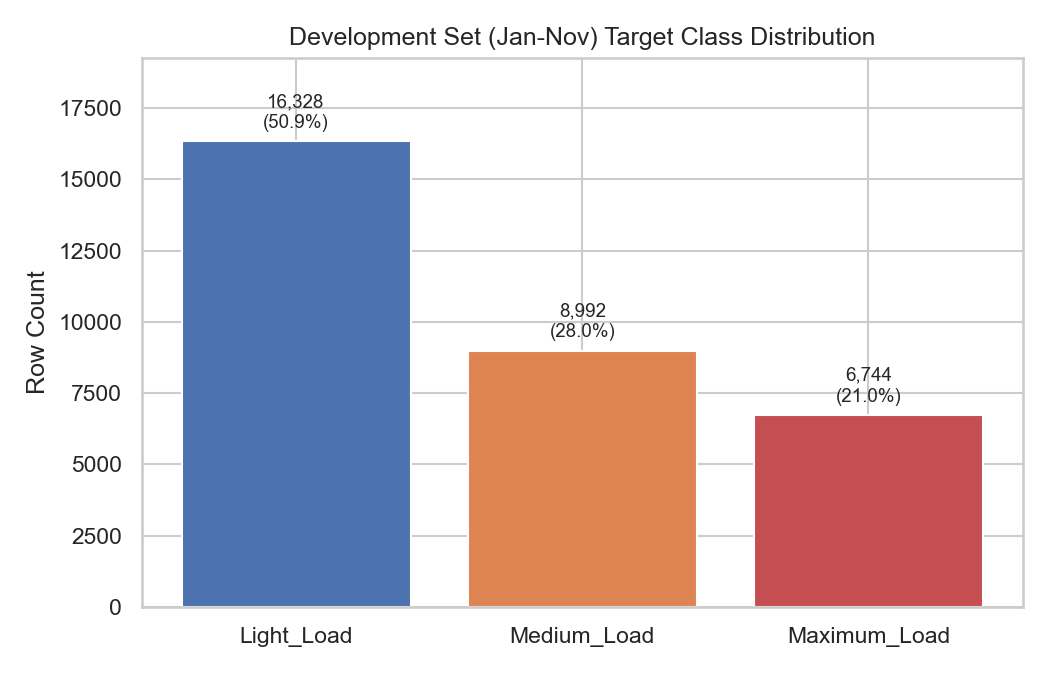

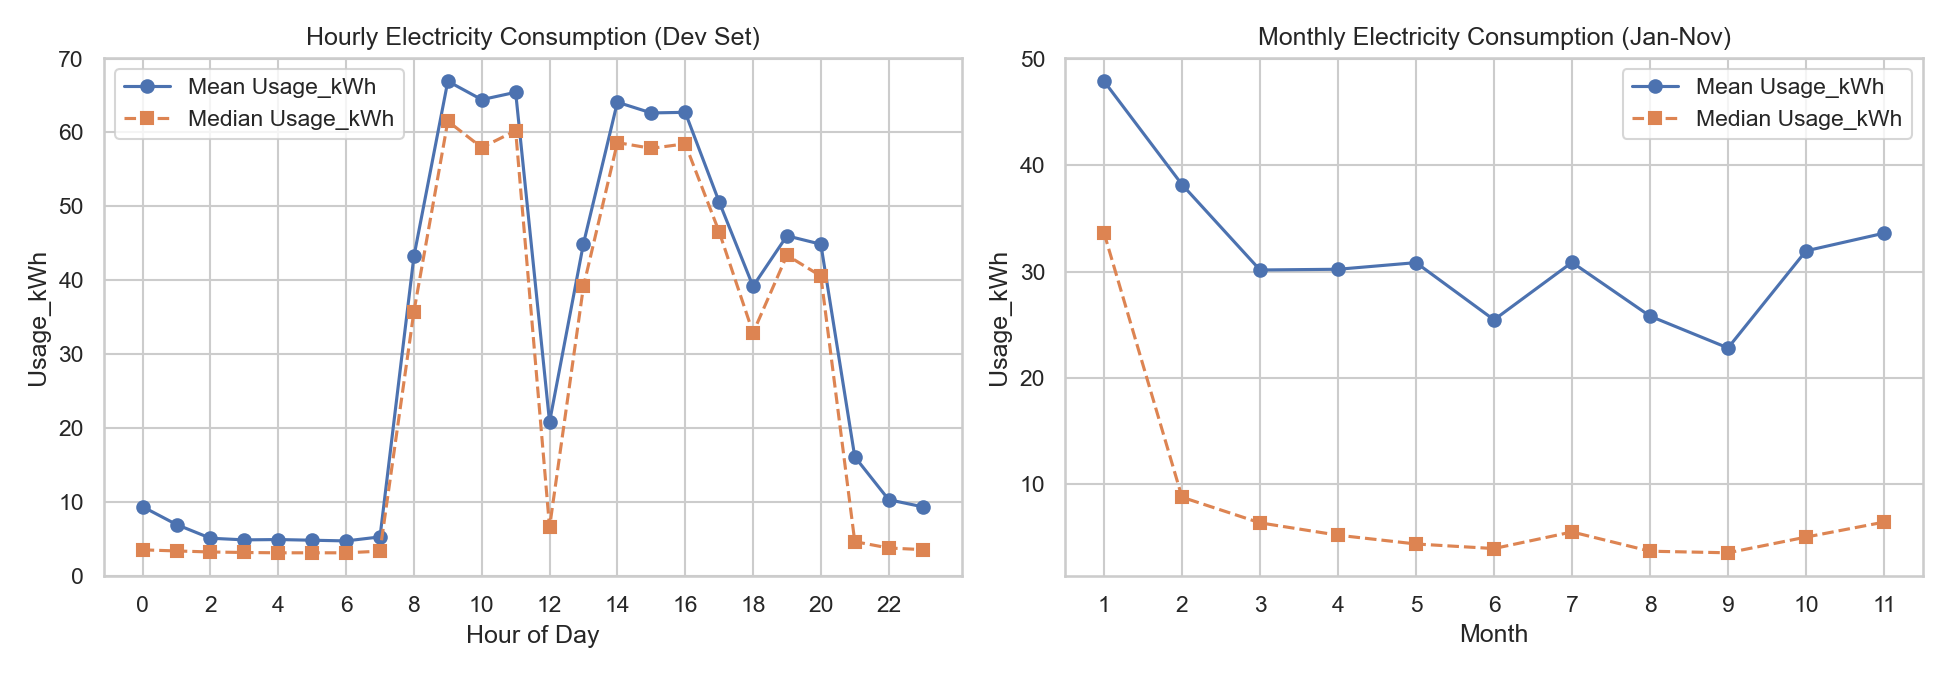

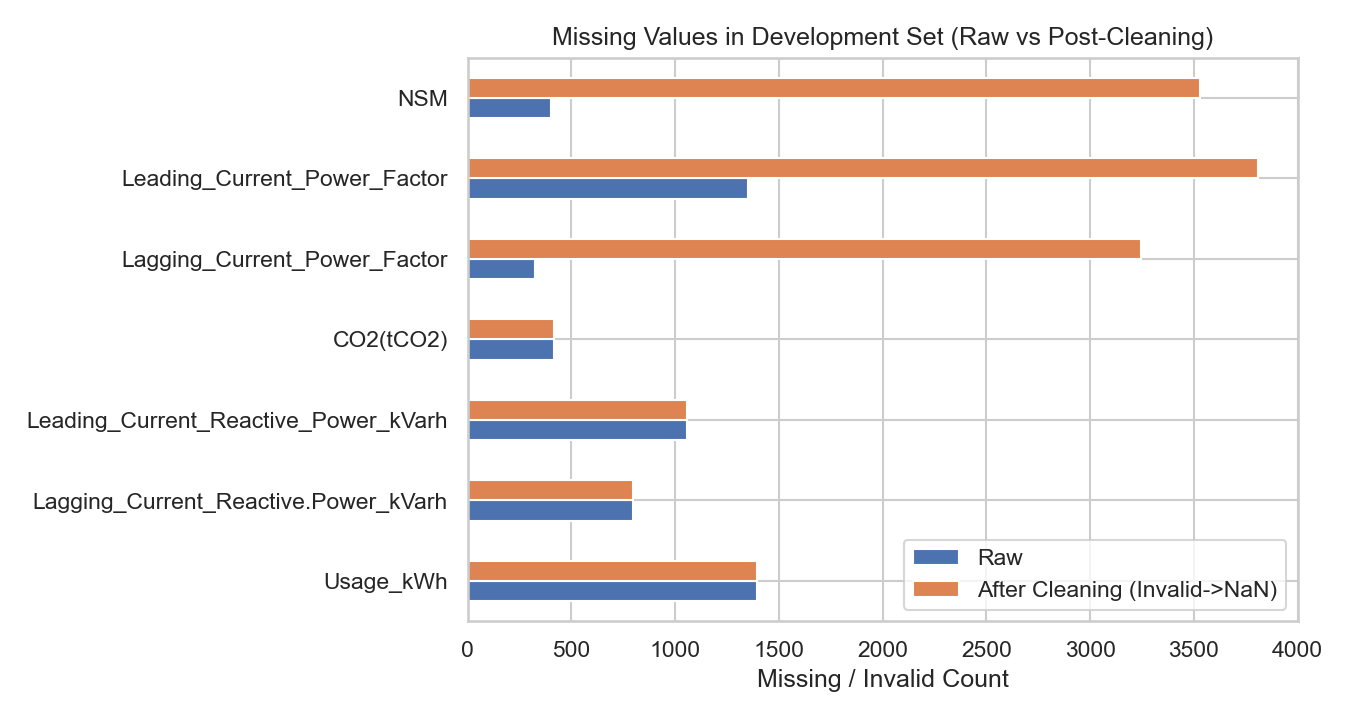

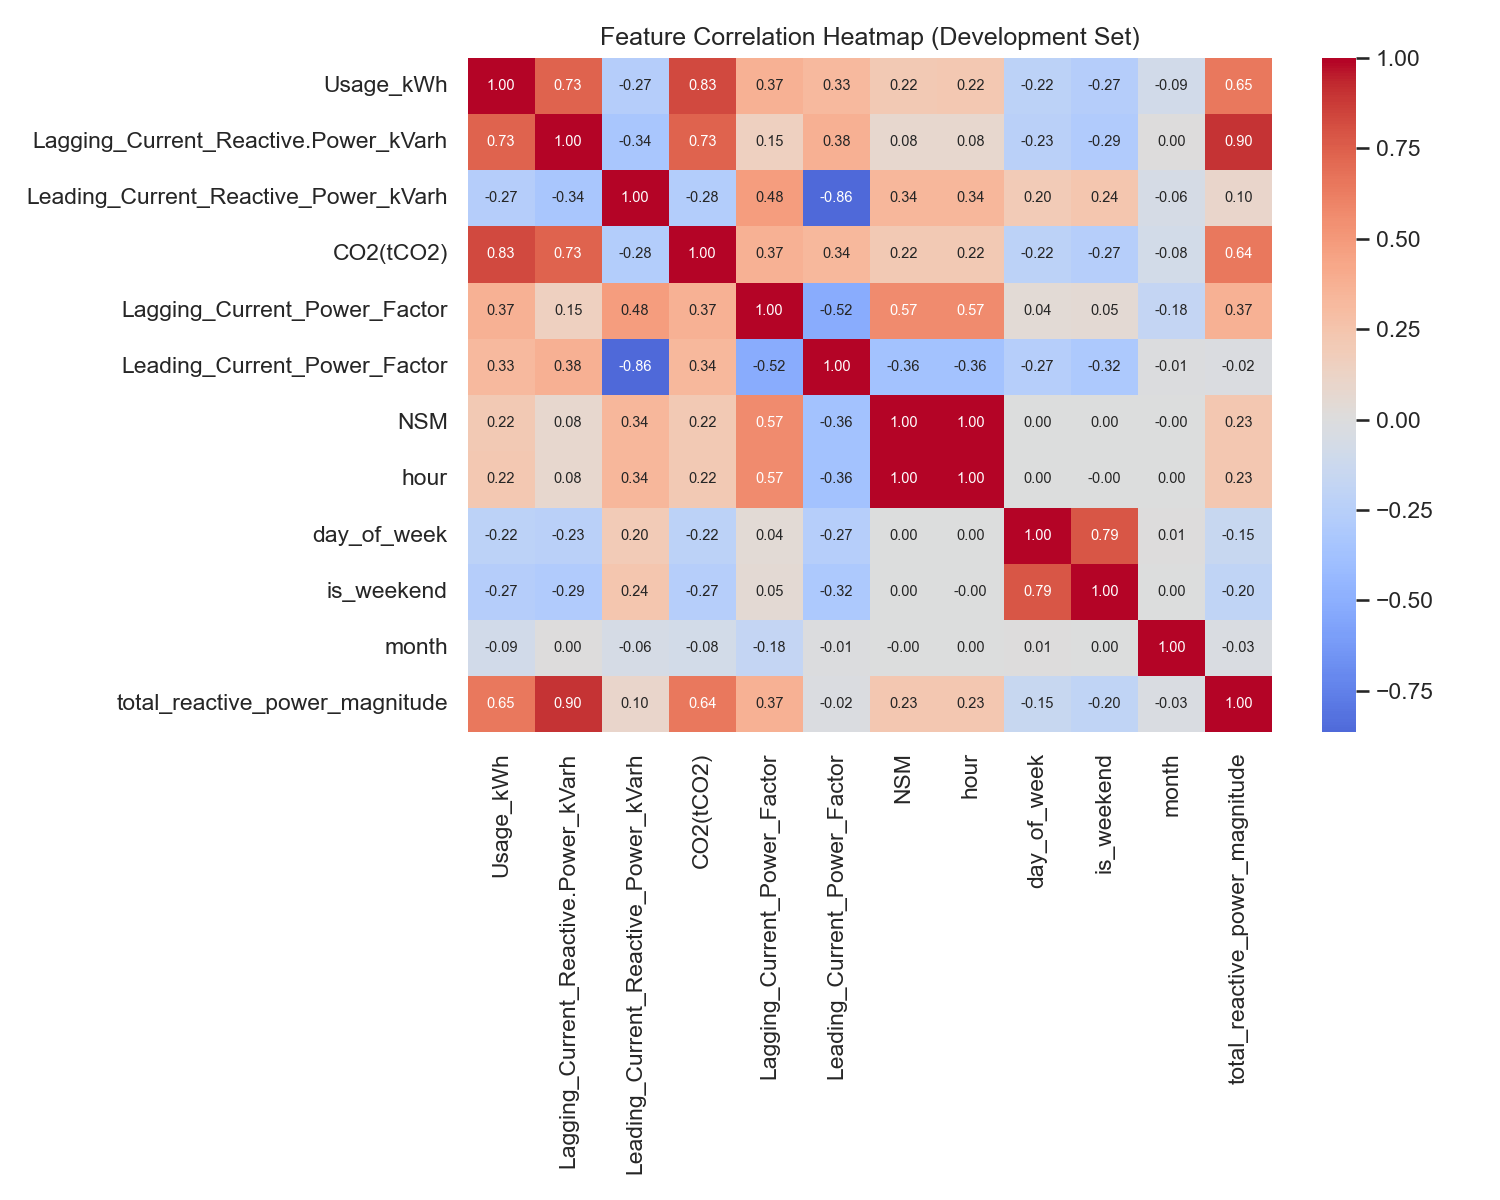

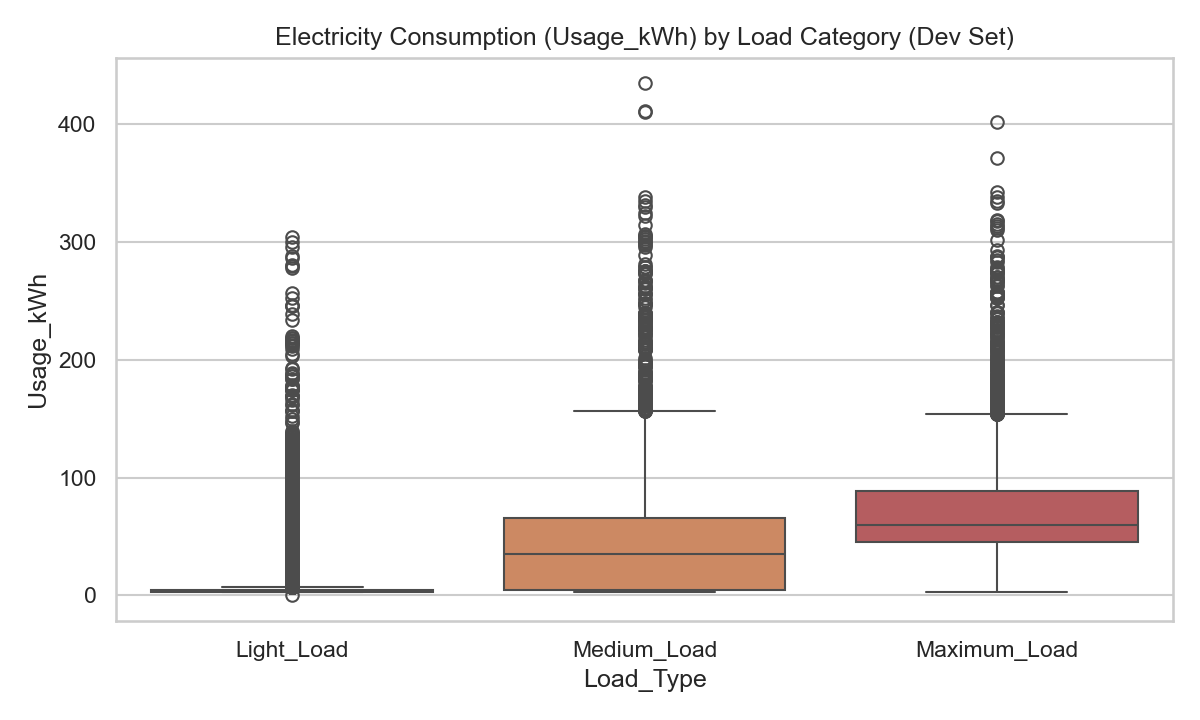

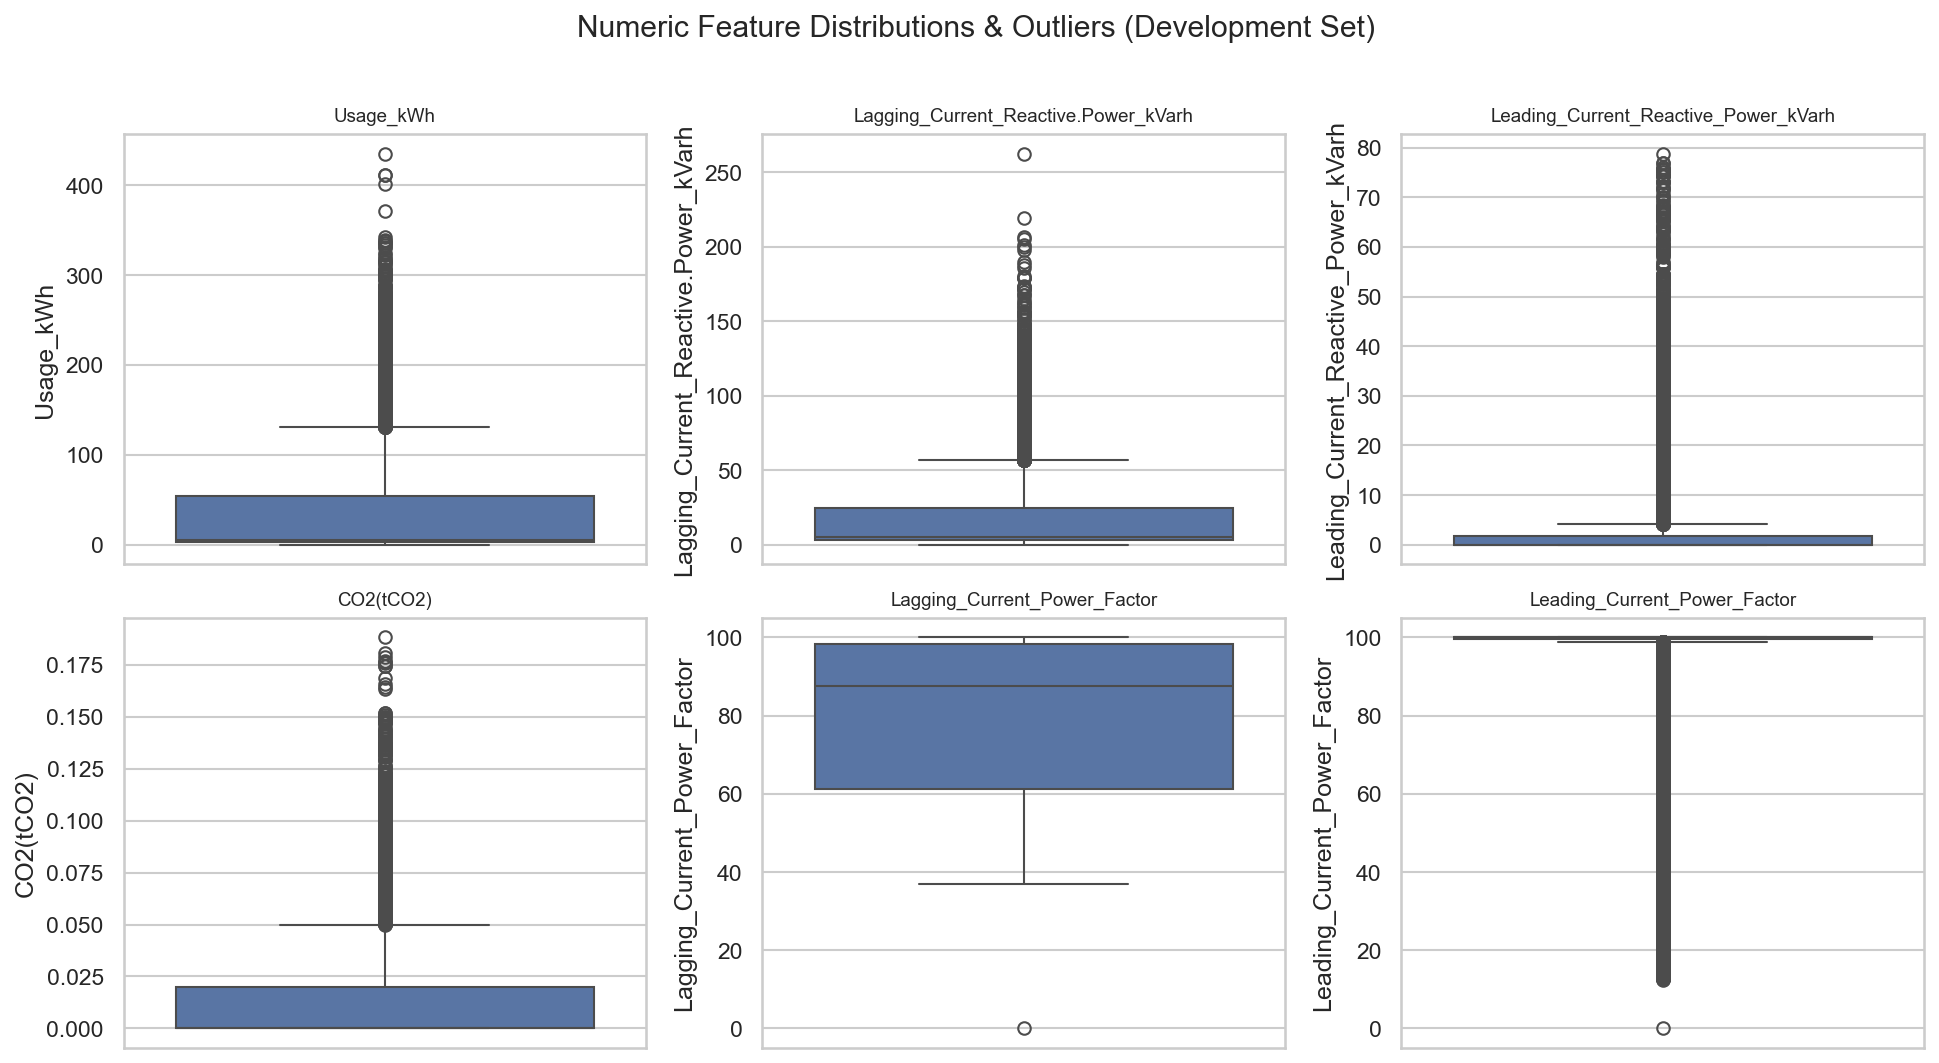

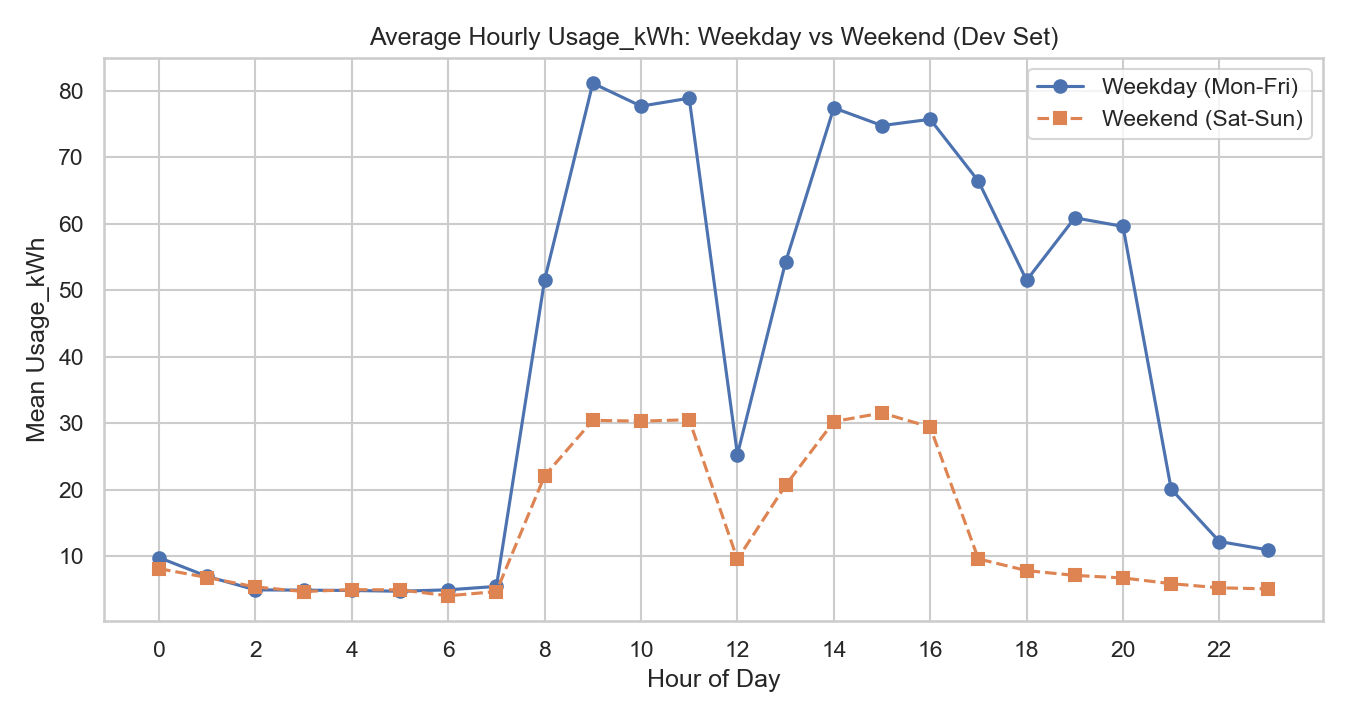

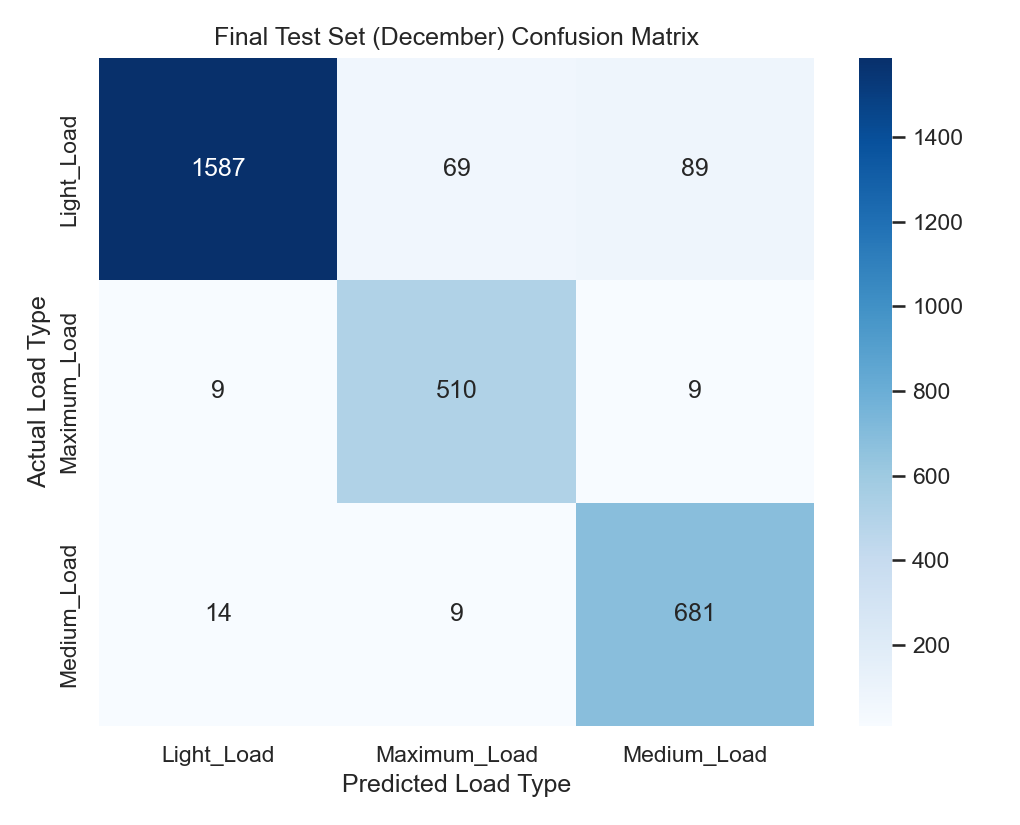

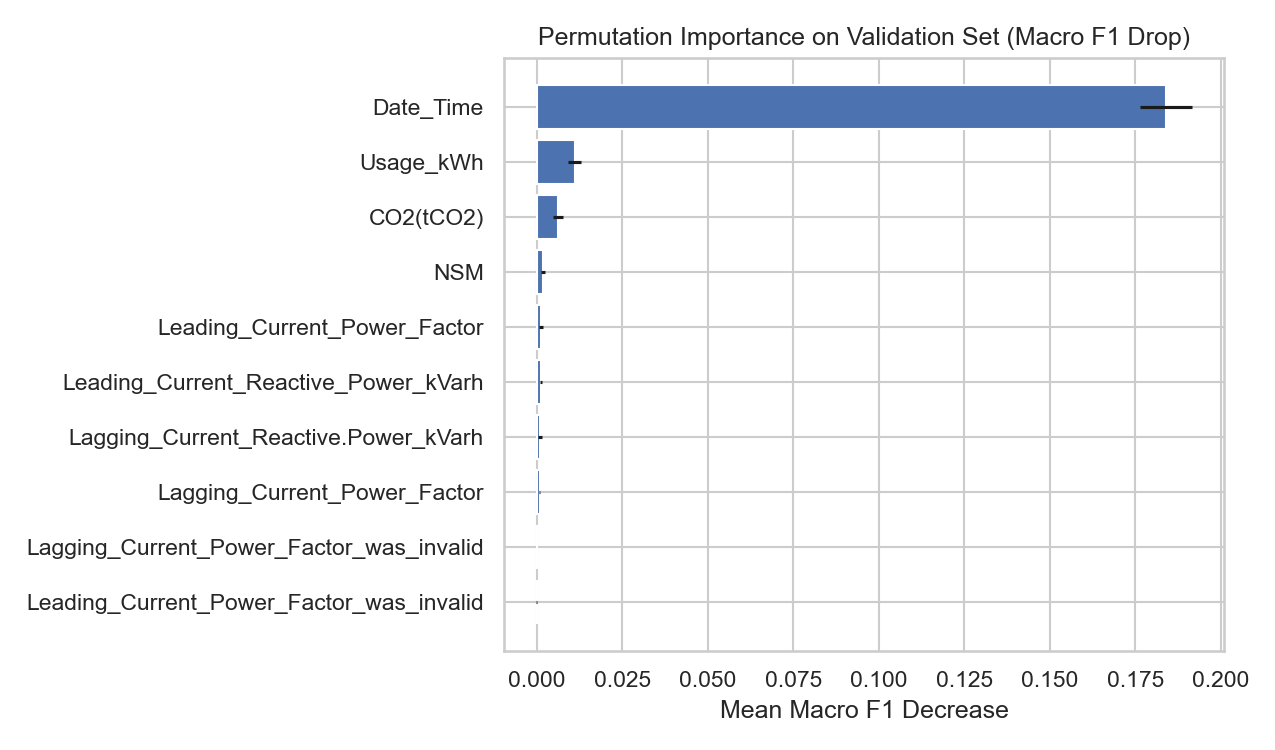

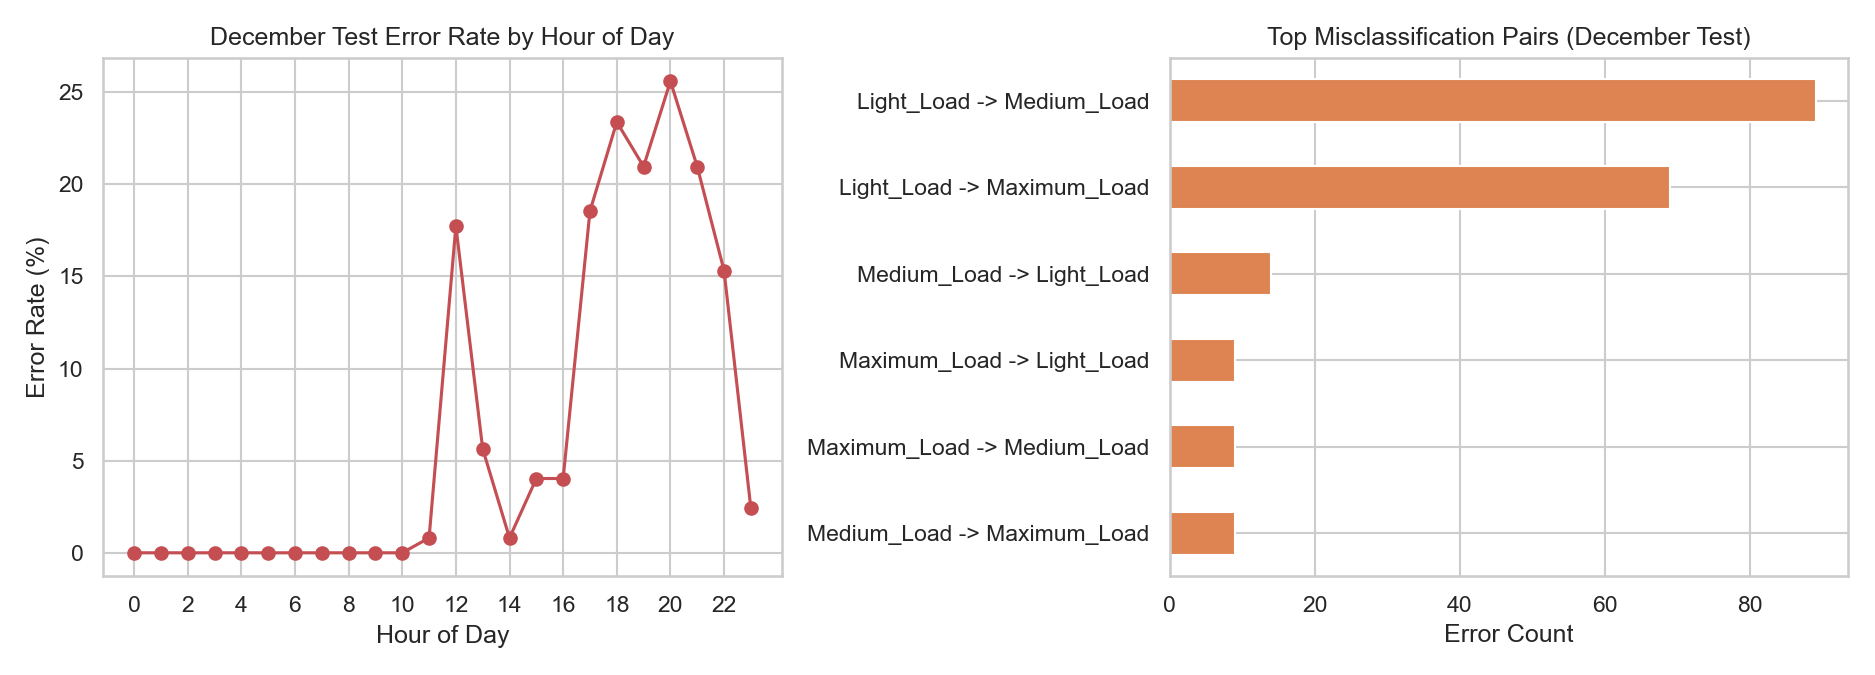

In [4]:
import pandas as pd
from IPython.display import Image, display
from src.load_prediction.eda import generate_eda_figures

raw_sorted = raw_df.sort_values("Date_Time", kind="mergesort").reset_index(drop=True)
raw_dev = raw_sorted.loc[raw_sorted["Date_Time"] <= val_df["Date_Time"].max()]
dev_df = pd.concat([train_df, val_df], ignore_index=True)

figures_dir = PROJECT_ROOT / "outputs" / "figures"
eda_summary = generate_eda_figures(dev_df, raw_dev, figures_dir)
print(json.dumps(eda_summary, indent=2))

for fig_name in eda_summary["figures_generated"]:
    display(Image(filename=str(figures_dir / fig_name)))

## Phase 5 — Feature Engineering & Feature-Set Comparison

We derive deterministic time features (`hour`, `day_of_week`, `is_weekend`, `month`, `hour_sin`, `hour_cos`, `ts_nsm`), `total_reactive_power_magnitude`, and anomaly/missingness indicators, then compare `timestamp_only`, `measurement_only`, and `combined` feature sets on `train (Jan–Oct) -> val (Nov)`.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from src.load_prediction.features import build_preprocessor

y_train, y_val = train_df["Load_Type"], val_df["Load_Type"]
fset_results = []
for fset in ("timestamp_only", "measurement_only", "combined"):
    for name, clf, scale in [
        ("LogisticRegression", LogisticRegression(max_iter=1000, random_state=42), True),
        ("RandomForest", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=2), False),
    ]:
        pipe = Pipeline([("prep", build_preprocessor(fset, scale_numeric=scale)), ("clf", clf)])
        pipe.fit(train_df, y_train)
        pred = pipe.predict(val_df)
        fset_results.append({
            "feature_set": fset,
            "model": name,
            "val_accuracy": round(float(accuracy_score(y_val, pred)), 4),
            "val_macro_f1": round(float(f1_score(y_val, pred, average="macro")), 4),
        })

pd.DataFrame(fset_results)

,feature_set,model,val_accuracy,val_macro_f1
0,timestamp_only,LogisticRegression,0.5632,0.4718
1,timestamp_only,RandomForest,0.6639,0.5753
2,measurement_only,LogisticRegression,0.6010,0.5260
3,measurement_only,RandomForest,0.6896,0.6119
4,combined,LogisticRegression,0.6191,0.5495
5,combined,RandomForest,0.6809,0.5940


## Phase 6 — Baseline and ML Model Training

All candidate models (`DummyClassifier`, `LogisticRegression`, `DecisionTree`, `RandomForest`, `HistGradientBoosting`, `XGBoost`, and optional `LightGBM`) are trained on `Jan–Oct` and evaluated on `Nov` using the same chronological validation strategy.

In [6]:
from src.load_prediction.train import evaluate_candidates, tune_top_models

comparison_df = evaluate_candidates(train_df, val_df, feature_set="combined")
comparison_df.to_csv(PROJECT_ROOT / "outputs" / "model_comparison.csv", index=False)
comparison_df[["model", "status", "train_time_sec", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1"]]

C:\Users\NIKHIL_007\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\compat.py:105: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


,model,status,train_time_sec,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,RandomForest,ok,2.017,0.6813,0.5940,0.5948,0.5944,0.6797
1,XGBoost,ok,1.381,0.6778,0.5919,0.5925,0.5922,0.6766
2,HistGradientBoosting,ok,3.827,0.6774,0.5912,0.5919,0.5915,0.6761
3,DecisionTree,ok,0.153,0.6767,0.5886,0.5905,0.5893,0.6727
4,LogisticRegression,ok,0.585,0.6191,0.5526,0.5473,0.5495,0.6267
5,DummyClassifier,ok,0.061,0.4750,0.1583,0.3333,0.2147,0.3059
6,LightGBM,skipped: No module named 'lightgbm',NaN,NaN,NaN,NaN,NaN,NaN


## Phase 7 — Hyperparameter Tuning (Chronological TimeSeriesSplit)

Using `RandomizedSearchCV` with `TimeSeriesSplit(n_splits=3)` on **development data (`Jan–Nov`) only** (December remains untouched), optimizing **Macro F1** and investigating `class_weight` and feature sets (`combined` vs `measurement_only`).

In [7]:
tuning_results = tune_top_models(dev_df, n_splits=3, n_iter=4)
(PROJECT_ROOT / "outputs" / "tuning_results.json").write_text(json.dumps(tuning_results, indent=2), encoding="utf-8")
print("Winning configuration:")
print(json.dumps(tuning_results["winner"], indent=2))
pd.DataFrame(tuning_results["candidates"])

Tuning RandomForest (combined)...


Tuning HistGradientBoosting (combined)...


Tuning RandomForest_measurement_only (measurement_only)...


Tuning XGBoost (combined)...


Winning configuration:
{
  "name": "RandomForest",
  "feature_set": "combined",
  "best_cv_macro_f1": 0.9082,
  "best_params": {
    "n_estimators": 250,
    "min_samples_leaf": 1,
    "max_depth": 15,
    "class_weight": "balanced_subsample"
  },
  "search_time_sec": 29.936
}


,name,feature_set,best_cv_macro_f1,best_params,search_time_sec
0,RandomForest,combined,0.9082,"{'n_estimators': 250, 'min_samples_leaf': 1, '...",29.936
1,XGBoost,combined,0.9028,"{'subsample': 0.8, 'n_estimators': 250, 'max_d...",31.122
2,HistGradientBoosting,combined,0.8981,"{'min_samples_leaf': 20, 'max_iter': 300, 'max...",17.847
3,RandomForest_measurement_only,measurement_only,0.7952,"{'n_estimators': 250, 'min_samples_leaf': 5, '...",24.217


## Phase 8 — Final Model Evaluation (Held-Out December Test Set)

The locked winning configuration (`RandomForestClassifier` with `combined` features, `n_estimators=250`, `max_depth=15`, `class_weight="balanced_subsample"`) is refitted on all **January–November (`32,064` rows)** development data and evaluated **once** on **December (`2,977` rows)**.

{
  "accuracy": 0.9332,
  "macro_precision": 0.9091,
  "macro_recall": 0.9476,
  "macro_f1": 0.9261,
  "weighted_precision": 0.9383,
  "weighted_recall": 0.9332,
  "weighted_f1": 0.9338,
  "f1_Light_Load": 0.9461,
  "f1_Maximum_Load": 0.914,
  "f1_Medium_Load": 0.9184
}


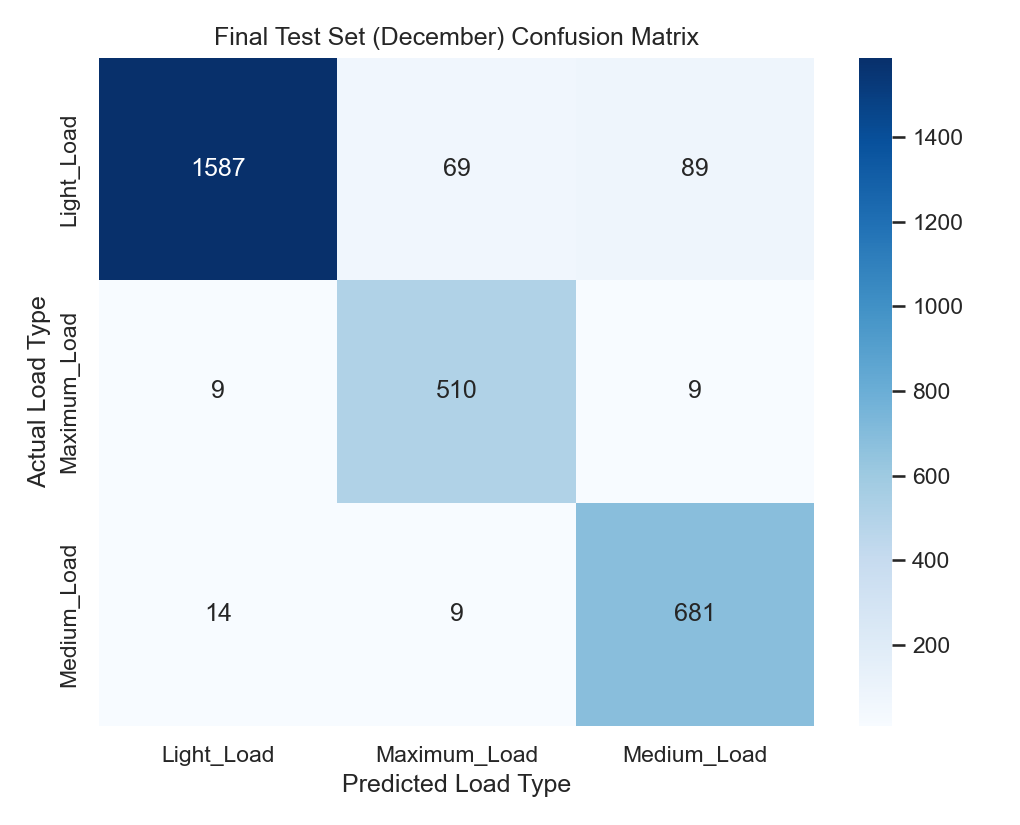

,Date_Time,actual_load_type,predicted_load_type,prob_Light_Load,prob_Maximum_Load,prob_Medium_Load
0,2018-12-01 00:00:00,Light_Load,Light_Load,1.000,0.000,0.0
1,2018-12-01 00:15:00,Light_Load,Light_Load,1.000,0.000,0.0
2,2018-12-01 00:30:00,Light_Load,Light_Load,1.000,0.000,0.0
3,2018-12-01 00:45:00,Light_Load,Light_Load,0.984,0.016,0.0
4,2018-12-01 01:00:00,Light_Load,Light_Load,1.000,0.000,0.0


In [8]:
from src.load_prediction.evaluate import evaluate_final_model, run_explainability_and_error_analysis

pred_df, metrics_payload, best_pipe = evaluate_final_model(
    dev_df, test_df, tuning_results["winner"], PROJECT_ROOT / "outputs", PROJECT_ROOT / "models"
)
print(json.dumps(metrics_payload["summary_metrics"], indent=2))
display(Image(filename=str(figures_dir / "08_confusion_matrix.png")))
pred_df.head()

## Phase 9 — Model Explainability and Error Analysis

- **Permutation Importance** is computed on the November validation set (`2,880` rows) using the Jan–Oct fitted model so there is zero test leakage.
- **Descriptive Error Analysis** examines the `199` December misclassifications (`6.68%` error rate): weekday error rate is `3.42%` vs. `13.54%` on weekends, with most errors being `Light_Load` predicted as `Medium_Load` (`89`) or `Maximum_Load` (`69`)—reflecting holiday/December schedule shifts.

{
  "total_test_rows": 2977,
  "total_errors": 199,
  "overall_error_rate": 0.0668,
  "weekday_error_rate": 0.0342,
  "weekend_error_rate": 0.1354,
  "confusion_pairs": {
    "Light_Load -> Medium_Load": 89,
    "Light_Load -> Maximum_Load": 69,
    "Medium_Load -> Light_Load": 14,
    "Maximum_Load -> Light_Load": 9,
    "Maximum_Load -> Medium_Load": 9,
    "Medium_Load -> Maximum_Load": 9
  }
}


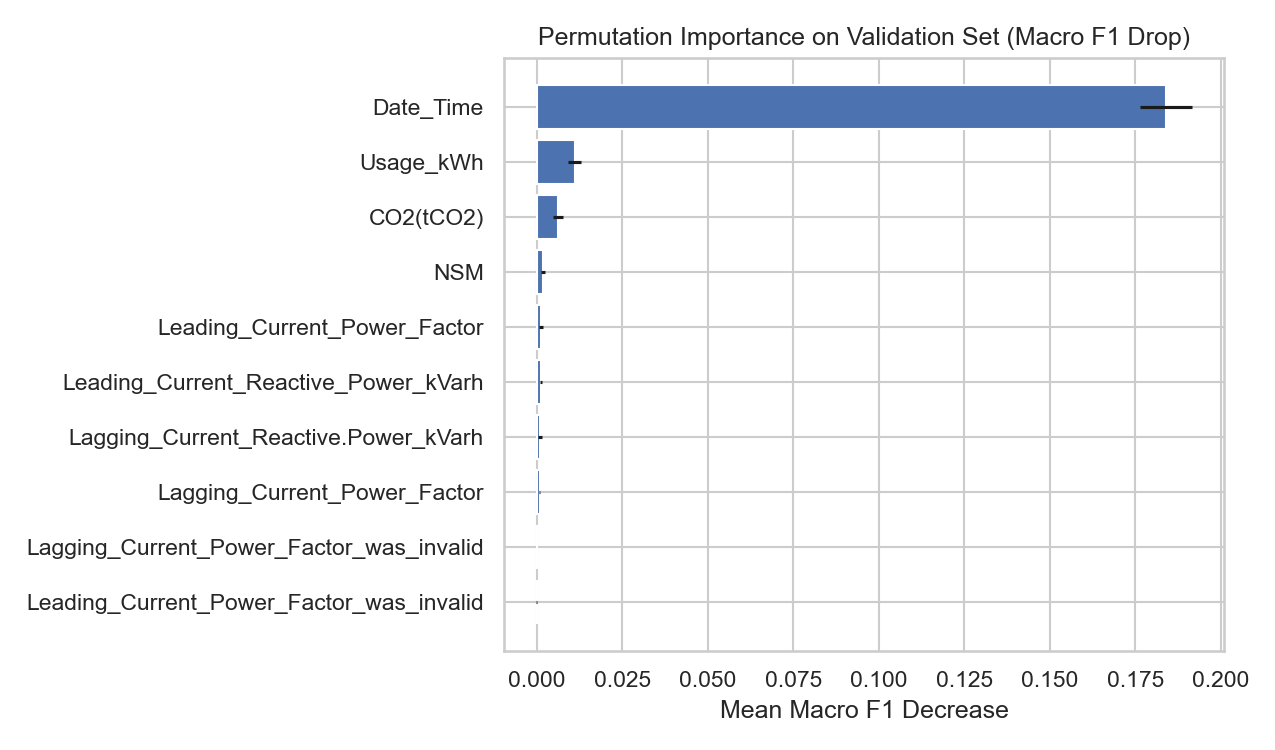

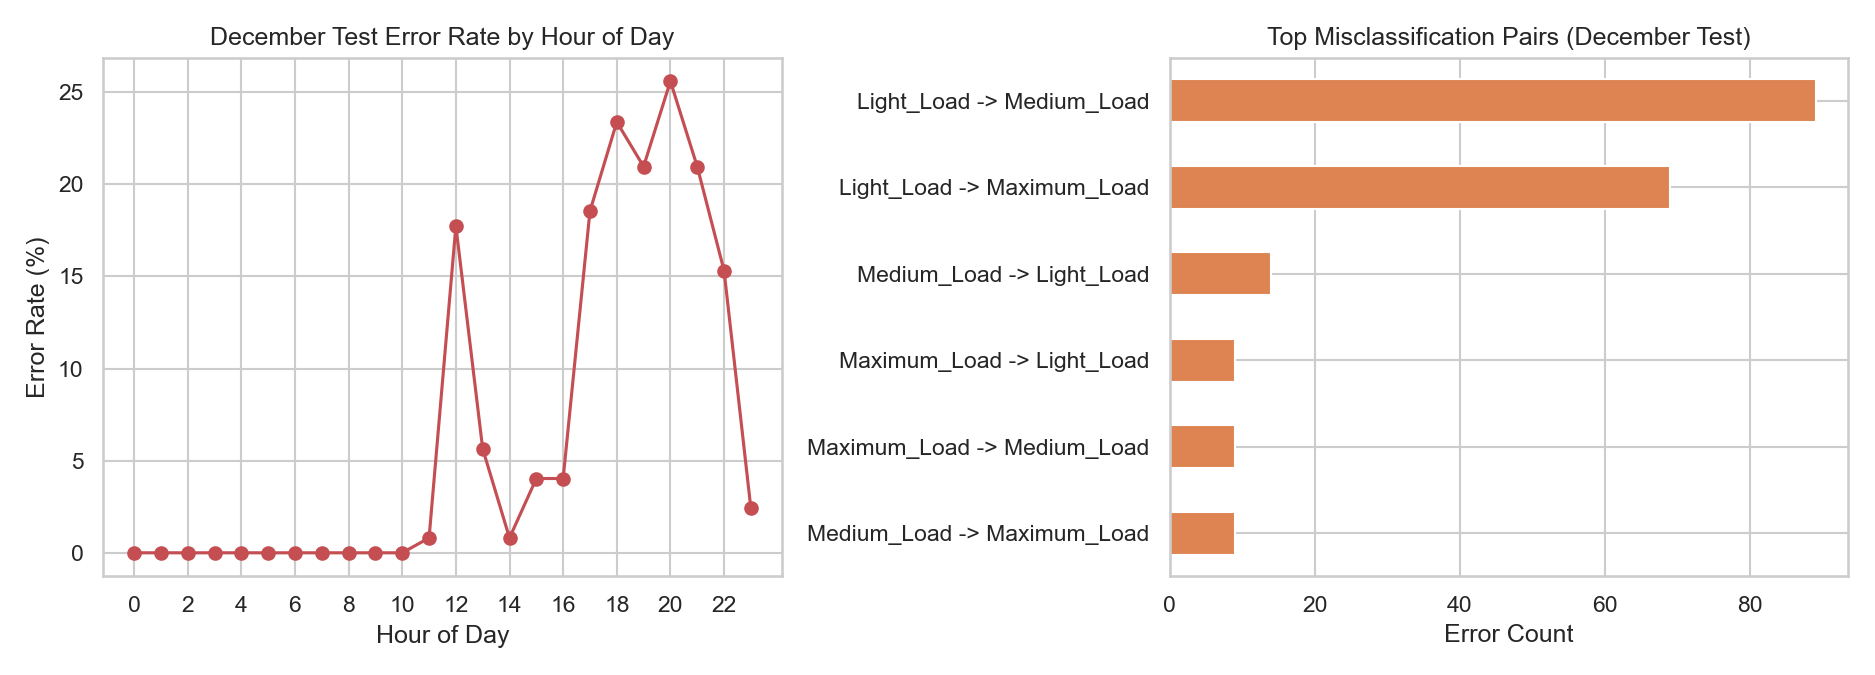

In [9]:
explain_payload = run_explainability_and_error_analysis(
    train_df, val_df, test_df, pred_df, tuning_results["winner"], PROJECT_ROOT / "outputs"
)
print(json.dumps(explain_payload["test_error_summary"], indent=2))
display(Image(filename=str(figures_dir / "09_permutation_importance.png")))
display(Image(filename=str(figures_dir / "10_error_analysis.png")))

## Phase 10 — Model Persistence and Inference Verification

Reload `models/best_model.joblib` (only load trusted `.joblib` files) and verify single-record and batch inference consistency.

In [10]:
from src.load_prediction.predict import load_trained_pipeline, predict_single, predict_batch

reloaded_pipe = load_trained_pipeline(PROJECT_ROOT / "models" / "best_model.joblib")
sample_record = test_df.drop(columns=["Load_Type"]).iloc[0].to_dict()
sample_record["Date_Time"] = sample_record["Date_Time"].strftime("%d-%m-%Y %H:%M")
print("Single-record prediction:", predict_single(sample_record, model=reloaded_pipe))

batch_check = predict_batch(test_df.drop(columns=["Load_Type"]).head(10), model=reloaded_pipe)
batch_check

Single-record prediction: {'Date_Time': '2018-12-01 00:00:00', 'predicted_load_type': 'Light_Load', 'prob_Light_Load': 1.0, 'prob_Maximum_Load': 0.0, 'prob_Medium_Load': 0.0}


,Date_Time,predicted_load_type,prob_Light_Load,prob_Maximum_Load,prob_Medium_Load
0,2018-12-01 00:00:00,Light_Load,1.000,0.000,0.0
1,2018-12-01 00:15:00,Light_Load,1.000,0.000,0.0
2,2018-12-01 00:30:00,Light_Load,1.000,0.000,0.0
3,2018-12-01 00:45:00,Light_Load,0.984,0.016,0.0
4,2018-12-01 01:00:00,Light_Load,1.000,0.000,0.0
5,2018-12-01 01:15:00,Light_Load,1.000,0.000,0.0
6,2018-12-01 01:30:00,Light_Load,1.000,0.000,0.0
7,2018-12-01 01:45:00,Light_Load,1.000,0.000,0.0
8,2018-12-01 02:00:00,Light_Load,1.000,0.000,0.0
9,2018-12-01 02:15:00,Light_Load,1.000,0.000,0.0
